In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn as sns


In [170]:
df = pd.read_csv("csv/train.csv")
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [171]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


# Vérifie si il y a des lignes doubles

In [172]:
df.duplicated().sum()

np.int64(0)

Si double : ``drop_duplicates()``

# Remplacement des NaN

In [173]:
#Vérification des NaN

round((df.isna().mean() * 100),2)

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

Traitement de la colonne Cabin

In [174]:
df_clean = df.drop(columns=['Cabin'])

La colonne Cabin a été supprimée car elle présente plus de 75 % de valeurs manquantes. Son taux élevé de données absentes rend son exploitation difficile et nécessiterait un traitement important pour conserver cette variable. Afin de simplifier le nettoyage et d'éviter d'introduire des données artificielles potentiellement biaisées, nous avons choisi de la retirer du dataset.

Traitement de la Colonne Age

In [175]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

Remplacement des valeurs nulls pour l'age par la mediane

In [176]:
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

Traitement de la Colonne Embarked

Affiche les passagers sans valeur dans Embarked

In [177]:
masks = df_clean["Embarked"].isna()==True

df_clean[masks]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,NaN


On retire les 2 personnes sans valeur dans "Embarked", on considère qu'elles ont acheté un ticket mais sans embarquer sur le navire.

In [178]:
df_clean = df_clean.dropna(subset=["Embarked"])

df_clean.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

# Outliers

Analyse des valeurs extrêmes (outliers) à l'aide de BoxPlot

{'whiskers': [<matplotlib.lines.Line2D at 0x148ea0b6cf0>,
 'caps': [<matplotlib.lines.Line2D at 0x148ea0b6f90>,
 'boxes': [<matplotlib.lines.Line2D at 0x148ea0b6ba0>],
 'medians': [<matplotlib.lines.Line2D at 0x148ea0b7230>],
 'fliers': [<matplotlib.lines.Line2D at 0x148ea0b7380>],
 'means': []}

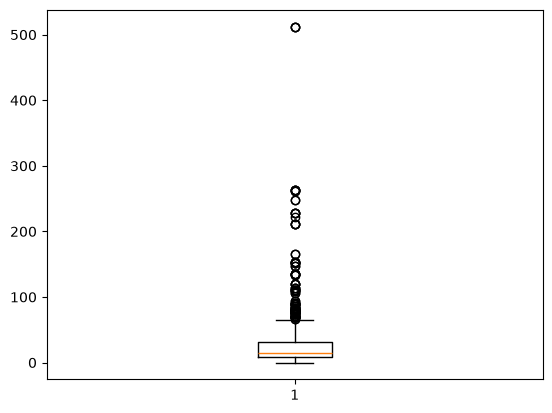

In [179]:
# Sur le prix
plt.boxplot(df_clean["Fare"])

Affichage des Outliers dans le dataframe

In [180]:
p = df_clean["Fare"] > 500

df_clean[p]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,C
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,C


{'whiskers': [<matplotlib.lines.Line2D at 0x148ea0b4590>,
 'caps': [<matplotlib.lines.Line2D at 0x148ea0b42f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x148ea0b4050>],
 'medians': [<matplotlib.lines.Line2D at 0x148ea0b4830>],
 'fliers': [<matplotlib.lines.Line2D at 0x148ea0b46e0>],
 'means': []}

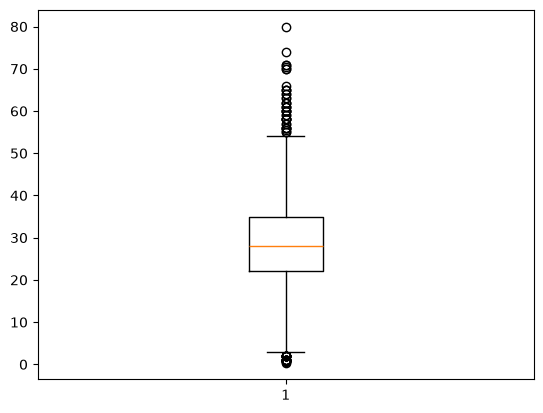

In [181]:
# Sur l'âge
plt.boxplot(df_clean["Age"])

In [182]:
#Verif Outliers sur les classes
df_clean["Pclass"].value_counts()

Pclass
3    491
1    214
2    184
Name: count, dtype: int64

Après analyse des BoxPlots des variables Age et Fare, aucun traitement spécifique des outliers n'a été jugé nécessaire. Les valeurs extrêmes observées semblent cohérentes avec la réalité des données et peuvent apporter des informations pertinentes au modèle de prédiction. Elles sont donc conservées dans le DataFrame.

# Ajout de deux nouvelles variables par Feature Engineering

In [183]:
# Ajout colonne WithoutFam (Voyage Seul)
def isSolo (df):
    if df["SibSp"] == 0 and df["Parch"] == 0 :
        return 1
    else :
        return 0
        
df_clean["WithoutFam"] = df_clean.apply(isSolo, axis = 1)

In [184]:
# Ajout colonne Title

df_clean["Title"] = df_clean["Name"].str.extract(r',\s*(\w+)\.')

# Encodage

In [185]:
# Encodage Sex
df_clean["Sex"] = df_clean["Sex"].replace({"female" : 0, "male" : 1}).astype(int)
df_clean = df_clean.rename(columns={"Sex" : "Male"})

In [186]:
# Encodage Embarked
df_clean = pd.get_dummies(df_clean,columns=["Embarked"], drop_first=True, dtype=int)

In [187]:
# Encodage Title
df_clean = pd.get_dummies(df_clean,columns=["Title"],drop_first=True,dtype=int)

# Suppression des colonnes avec justifications

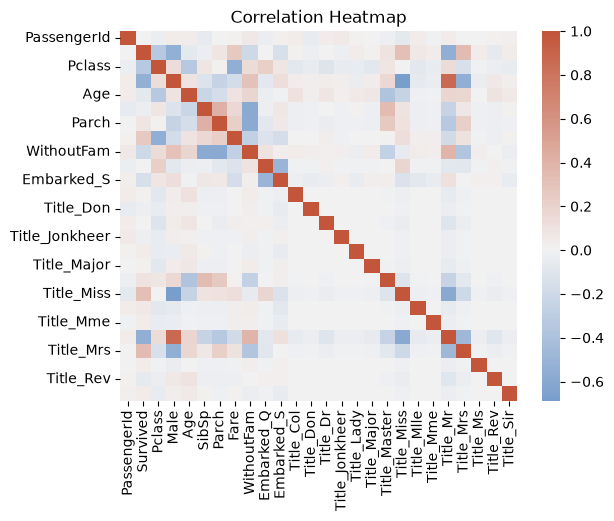

In [188]:
sns.heatmap(df_clean.select_dtypes(include='number').corr(), cmap=sns.diverging_palette(250, 20, as_cmap=True), center=0)
plt.title("Correlation Heatmap")
plt.show()

In [189]:
correlation = df_clean.corr(numeric_only=True)

correlation["Survived"]

PassengerId      -0.005028
Survived          1.000000
Pclass           -0.335549
Male             -0.541585
Age              -0.069822
SibSp            -0.034040
Parch             0.083151
Fare              0.255290
WithoutFam       -0.206207
Embarked_Q        0.004536
Embarked_S       -0.151777
Title_Col         0.011485
Title_Don        -0.026409
Title_Dr          0.008454
Title_Jonkheer   -0.026409
Title_Lady        0.042642
Title_Major       0.011485
Title_Master      0.085998
Title_Miss        0.326352
Title_Mlle        0.060339
Title_Mme         0.042642
Title_Mr         -0.547689
Title_Mrs         0.337892
Title_Ms          0.042642
Title_Rev        -0.064871
Title_Sir         0.042642
Name: Survived, dtype: float64

Justification : Retire les colonnes qui selon la heatmap ne sont pas correlée avec Survived

- PassengerId : identifiant unique du passager, sans corrélation significative avec la survie (-0.005).

- Name : nom complet peu exploitable directement. Les informations pertinentes ont été extraites grâce à la création de la variable Title.

- Age : corrélation linéaire relativement faible avec la survie (-0.070). Choix de simplifier le modèle en réduisant le nombre de variables, malgré une possible information prédictive liée à l'âge.

- SibSp : faible corrélation avec la survie (-0.034). Information familiale partiellement reprise dans la variable WithoutFam.

- Parch : faible corrélation avec la survie (0.083). Information également partiellement représentée par WithoutFam.

- Ticket : référence de réservation présentant une forte cardinalité et nécessitant un traitement supplémentaire pour être exploitable.

In [190]:
df_clean = df_clean.drop(["PassengerId", "Name", "Age", "SibSp", "Parch", "Ticket"], axis =1)

df_clean

,Survived,Pclass,Male,Fare,WithoutFam,Embarked_Q,Embarked_S,Title_Col,Title_Don,Title_Dr,...,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir
0,0,3,1,7.2500,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,1,1,0,71.2833,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,1,3,0,7.9250,1,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,0,53.1000,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,3,1,8.0500,1,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,13.0000,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
887,1,1,0,30.0000,1,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
888,0,3,0,23.4500,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
889,1,1,1,30.0000,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


# Conversion en CSV

In [191]:
df_clean.to_csv("csv/train_clean.csv", index=False)